 **Step 1— Import Libraries**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


**Step 2-Uploading Dataset**

In [ ]:

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, sep=";", decimal=",")

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)

display(df.head())


Saving AirQualityUCI.csv to AirQualityUCI.csv
Dataset loaded successfully!
Original dataset shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


**Step 3-Clean the dataset**

The file has two empty columns and uses -200 to represent missing measurements. We will remove the empty columns and replace those missing-value markers with NaN.

In [ ]:

# Remove columns that contain no data
df = df.dropna(axis=1, how="all")

# Convert -200 missing-value markers to NaN
df = df.replace(-200, np.nan)

# Create a date-time column for plotting
df["DateTime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

# Convert measurement columns to numeric values
for col in df.columns:
    if col not in ["Date", "Time", "DateTime"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort observations chronologically
df = df.sort_values("DateTime").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values in each column:")
print(df.isnull().sum())

display(df.head())


Cleaned dataset shape: (9471, 16)

Missing values in each column:
Date              114
Time              114
CO(GT)           1797
PT08.S1(CO)       480
NMHC(GT)         8557
C6H6(GT)          480
PT08.S2(NMHC)     480
NOx(GT)          1753
PT08.S3(NOx)      480
NO2(GT)          1756
PT08.S4(NO2)      480
PT08.S5(O3)       480
T                 480
RH                480
AH                480
DateTime          114
dtype: int64


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


**Step 4-Explore the data**

Statistical summary:


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime
count,7674.000000,8991.000000,914.000000,8991.000000,8991.000000,7718.000000,8991.000000,7715.000000,8991.000000,8991.000000,8991.000000,8991.000000,8991.000000,9357
mean,2.152750,1099.833166,218.811816,10.083105,939.153376,246.896735,835.493605,113.091251,1456.264598,1022.906128,18.317829,49.234201,1.025530,2004-09-21 16:00:00
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,2004-03-10 18:00:00
25%,1.100000,937.000000,67.000000,4.400000,734.500000,98.000000,658.000000,78.000000,1227.000000,731.500000,11.800000,35.800000,0.736800,2004-06-16 05:00:00
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400,2004-09-21 16:00:00
75%,2.900000,1231.000000,297.000000,14.000000,1116.000000,326.000000,969.500000,142.000000,1674.000000,1273.500000,24.400000,62.500000,1.313700,2004-12-28 03:00:00
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,2005-04-04 14:00:00
std,1.453252,217.080037,204.459921,7.449820,266.831429,212.979168,256.817320,48.370108,346.206794,398.484288,8.832116,17.316892,0.403813,NaN


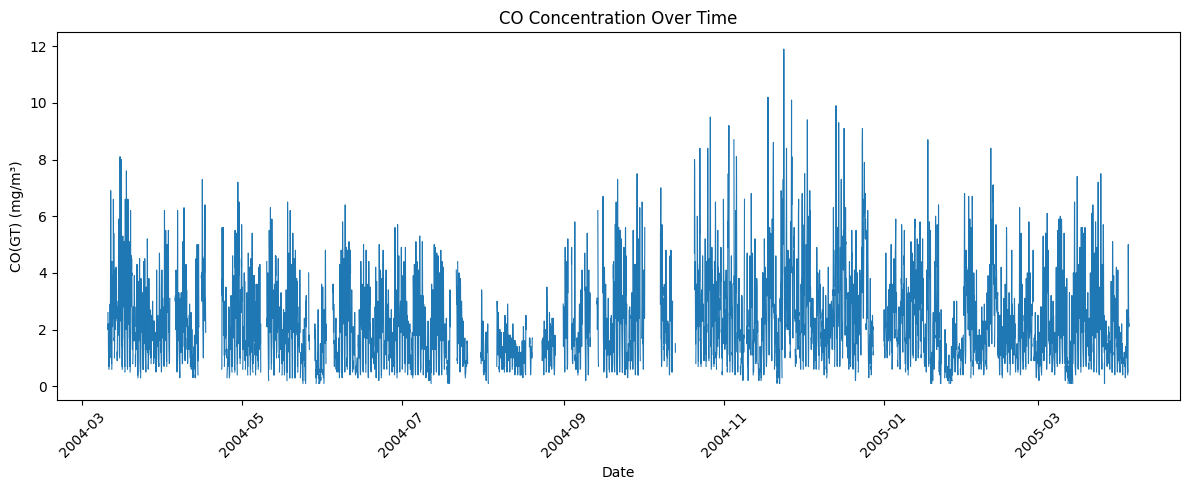

In [ ]:

print("Statistical summary:")
display(df.describe())

plt.figure(figsize=(12, 5))
plt.plot(df["DateTime"], df["CO(GT)"], linewidth=0.8)
plt.title("CO Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("CO(GT) (mg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The graph shows how measured carbon monoxide concentration changes over time. Missing readings will appear as gaps.

**Step 5-Select the prediction target and input features**

We will predict CO(GT), the measured carbon monoxide concentration, using the other available pollutant sensor measurements and environmental variables.

This is pollutant concentration estimation, not official AQI classification.

In [ ]:

# Remove rows where the target value is missing
df_model = df.dropna(subset=["CO(GT)"]).copy()

# Input features: all numeric measurements except the target
feature_cols = [
    col for col in df_model.select_dtypes(include=np.number).columns
    if col != "CO(GT)"
]

X = df_model[feature_cols]
y = df_model["CO(GT)"]

print("Input features:")
print(feature_cols)

print("\nTotal usable rows:", len(df_model))
print("Number of input features:", len(feature_cols))
print("Target variable: CO(GT)")

display(X.head())


Input features:
['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Total usable rows: 7674
Number of input features: 12
Target variable: CO(GT)


,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


**Step 6 — Split the data into training and testing sets**

In [ ]:

split_index = int(len(df_model) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 6139
Testing samples: 1535


**Step 7 — Train three machine learning models**

We will compare Linear Regression, Random Forest, and Gradient Boosting. Missing input measurements are filled using the median calculated from the training data only.

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")


Linear Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


**Linear Regression**: learns a linear relationship between inputs and CO concentration.



**Random Forest**: combines predictions from many decision trees.



**Gradient Boosting**:builds trees sequentially, with later trees correcting earlier errors.

**Step 8 — Evaluate the models**

We will compare MAE, RMSE, and \(R^2\). Lower MAE and RMSE are better; an \(R^2\) closer to 1 generally indicates a better fit.

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test RMSE:", best_model_name)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.3141,0.4959,0.8640
2,Gradient Boosting,0.3334,0.5039,0.8595
1,Random Forest,0.3900,0.5740,0.8177


Best model by test RMSE: Linear Regression


**Step 9 — Visualize actual vs predicted values**

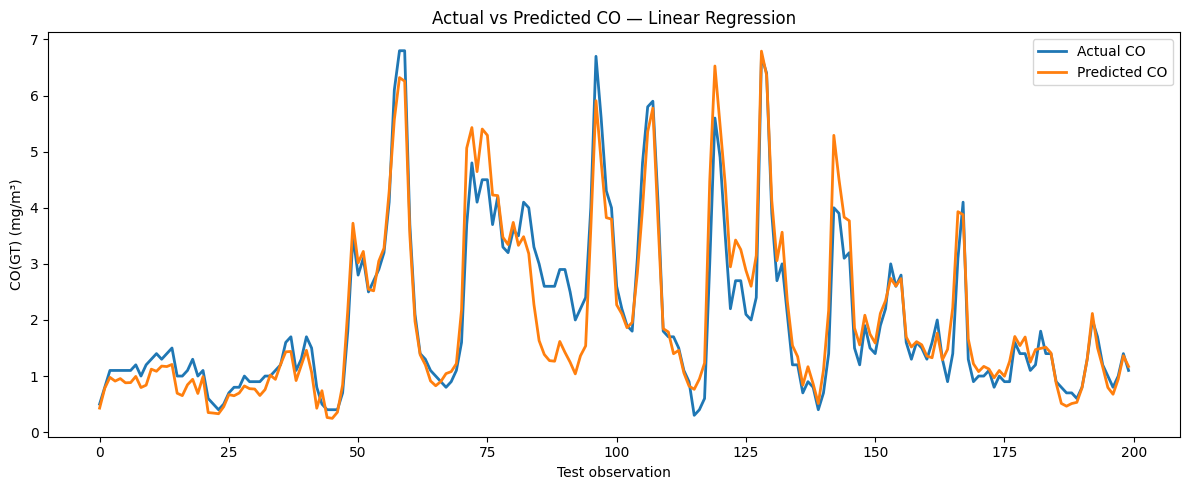

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.reset_index(drop=True).values[:200],
    label="Actual CO",
    linewidth=2
)

plt.plot(
    predictions[best_model_name][:200],
    label="Predicted CO",
    linewidth=2
)

plt.title(f"Actual vs Predicted CO — {best_model_name}")
plt.xlabel("Test observation")
plt.ylabel("CO(GT) (mg/m³)")
plt.legend()
plt.tight_layout()
plt.show()


The first 200 test observations are shown to keep the graph readable.

**Step 10 — Compare model performance visually**





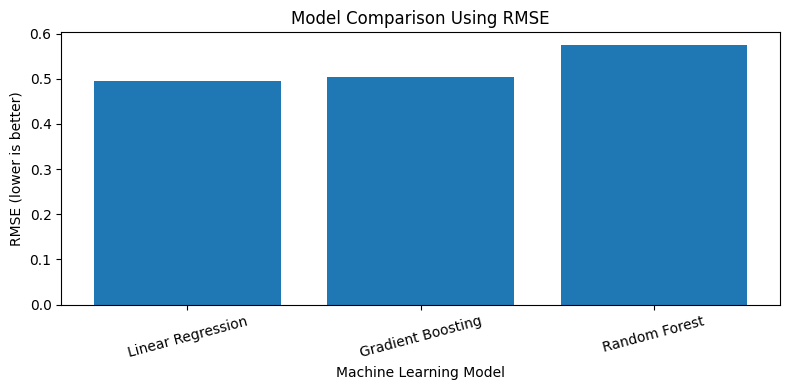

In [ ]:

plt.figure(figsize=(8, 4))

plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison Using RMSE")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Step 11 — Find the most important features**

,Feature,Importance
3,PT08.S2(NMHC),0.6194
2,C6H6(GT),0.1966
4,NOx(GT),0.0738
0,PT08.S1(CO),0.0236
6,NO2(GT),0.0203
5,PT08.S3(NOx),0.0176
9,T,0.0151
8,PT08.S5(O3),0.0100
7,PT08.S4(NO2),0.0075
11,AH,0.0071


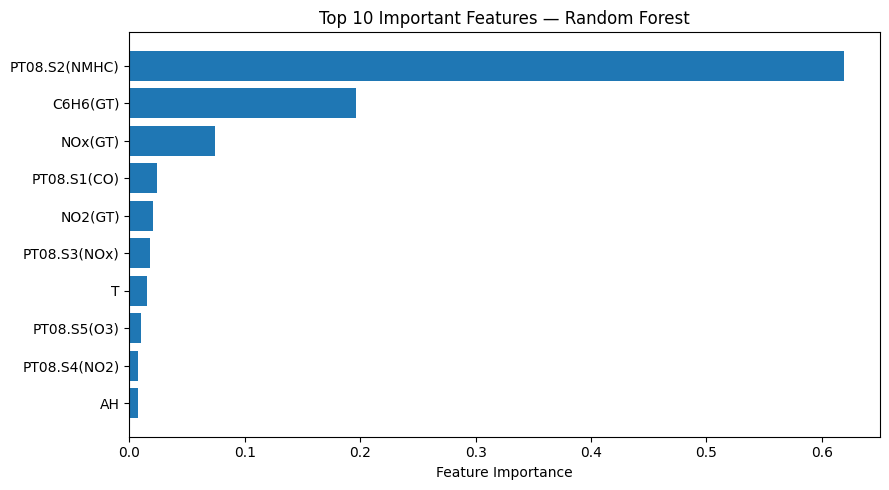

In [ ]:

rf_model = trained_models["Random Forest"].named_steps["model"]

importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(10).round(4))

plt.figure(figsize=(9, 5))
top_features = importance.head(10).sort_values("Importance")

plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Important Features — Random Forest")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


**Step 12 — Predict a sample CO concentration**

We'll use one observation from the test set to demonstrate a prediction on data the model did not train on.

In [ ]:

sample = X_test.iloc[[0]]
actual_value = y_test.iloc[0]

predicted_value = best_model.predict(sample)[0]

print("Selected model:", best_model_name)
print(f"Actual CO concentration: {actual_value:.2f} mg/m³")
print(f"Predicted CO concentration: {predicted_value:.2f} mg/m³")
print(f"Absolute error: {abs(actual_value - predicted_value):.2f} mg/m³")


Selected model: Linear Regression
Actual CO concentration: 0.50 mg/m³
Predicted CO concentration: 0.43 mg/m³
Absolute error: 0.07 mg/m³


In [ ]:

import joblib

model_package = {
    "model": best_model,
    "features": feature_cols,
    "target": "CO(GT)",
    "model_name": best_model_name
}

joblib.dump(model_package, "air_quality_model.pkl")

print("Model saved successfully!")
files.download("air_quality_model.pkl")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

results_df.to_csv("model_comparison.csv", index=False)
files.download("model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>